# Nhãn mua và cohort khách hàng

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Audit Any Product Cohorts

Nguồn: `src/audit_any_product_cohorts.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/audit_any_product_cohorts.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Audit any-product labels and historical sparsity; no raw edits or model fitting."""
from pathlib import Path
import json

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / 'docs/propensity_feasibility/any_product'


def main():
    labels = [f'target_{i}' for i in range(1, 5)]
    target = pq.read_table(ROOT / 'data/MBD-mini/targets',
                           columns=['client_id', 'mon'] + labels).to_pandas()
    assert not target.duplicated(['client_id', 'mon']).any()
    assert target[['client_id', 'mon']].notna().all().all()
    assert all(target[c].dropna().isin([0, 1]).all() for c in labels)
    known_positive = target[labels].eq(1).any(axis=1)
    known_negative = target[labels].eq(0).all(axis=1)
    target['any_product'] = pd.Series(pd.NA, index=target.index, dtype='Int8')
    target.loc[known_positive, 'any_product'] = 1
    target.loc[known_negative, 'any_product'] = 0
    target['month'] = pd.to_datetime(target.mon).dt.to_period('M').astype(str)
    monthly = target.groupby('month').agg(
        rows=('client_id', 'size'), clients=('client_id', 'nunique'),
        labelled=('any_product', 'count'), positives=('any_product', 'sum'))
    monthly['unknown'] = monthly.rows - monthly.labelled
    monthly['negative'] = monthly.labelled - monthly.positives
    monthly['positive_rate'] = monthly.positives / monthly.labelled

    # Trusted, locally generated cache from review_mbd_eda.py. Its month array
    # is object-typed. It counts observed raw logs, not complete-case events.
    cache_path = ROOT / 'outputs/mbd_review_cache/source_month_counts.npz'
    with np.load(cache_path, allow_pickle=True) as cache:
        cube = cache['counts']
        months = cache['months'].astype(str)
        ids = pd.Index(cache['client_ids'])
        fingerprint = str(cache['source_fingerprint'].item())
    assert ids.is_unique and cube.shape == (len(ids), len(months), 3)
    assert months.tolist() == sorted(months.tolist())
    assert set(target.client_id.astype(str)) == set(ids)
    assert np.array_equal(cube.sum(axis=(0, 1), dtype=np.uint64),
                          [38764930, 66295724, 217205])
    cutoff = '2022-12'
    frame = target[target.month.eq(cutoff)].copy()
    positions = ids.get_indexer(frame.client_id.astype(str))
    assert (positions >= 0).all()
    past = cube[:, months < cutoff, :].sum(axis=1, dtype=np.uint64)[positions]
    recent = cube[:, (months >= '2022-09') & (months < cutoff), :].sum(
        axis=1, dtype=np.uint64)[positions]
    total = past.sum(axis=1)
    source_n = (past > 0).sum(axis=1)
    cohorts = {
        'all_clients': np.ones(len(frame), dtype=bool),
        'no_events_all_available_history': total == 0,
        'has_history_no_events_last_3_calendar_months': (total > 0) & (recent.sum(axis=1) == 0),
        'has_events_last_3_calendar_months': recent.sum(axis=1) > 0,
        'trx_only_all_history': (past[:, 0] > 0) & (source_n == 1),
        'no_trx_but_geo_or_dialog_all_history': (past[:, 0] == 0) & (source_n > 0),
        'all_three_sources_all_history': source_n == 3,
        'one_to_nine_trx_all_history': (past[:, 0] >= 1) & (past[:, 0] < 10),
        'no_trx_last_3_calendar_months': recent[:, 0] == 0,
    }
    positive_total = int(frame.any_product.eq(1).sum())
    records = []
    for name, mask in cohorts.items():
        subset = frame.loc[mask, 'any_product']
        positive = int(subset.eq(1).sum())
        known = int(subset.notna().sum())
        records.append(dict(cohort=name, clients=len(subset), positives=positive,
                            unknown=int(subset.isna().sum()),
                            positive_rate=positive / known if known else None,
                            fraction_all_positives=positive / positive_total))
    summary = dict(
        checked_on='2026-11-08', rows=len(target), clients=target.client_id.nunique(),
        positive_rows=int(known_positive.sum()), negative_rows=int(known_negative.sum()),
        unknown_label_rows=int(target.any_product.isna().sum()),
        raw_label_null_cells=int(target[labels].isna().sum().sum()),
        positive_rate=float(known_positive.sum() / target.any_product.notna().sum()),
        expected_client_months=len(ids) * len(monthly),
        missing_client_month_rows=len(ids) * len(monthly) - len(target),
        cohort_cutoff='2022-12-01', cohort_label_month='2022-12',
        cohort_recent_history='[2022-09-01, 2022-12-01); three calendar months, not 84 days',
        cohort_history='All available cached raw events strictly before cutoff; includes partial boundary days.',
        source_fingerprint=fingerprint,
        cohort_note='Rows overlap except no-history / old-history-only / recent-history partition. Descriptive, not threshold tuning.',
        model_fitted=False,
    )
    assert summary['positive_rows'] + summary['negative_rows'] + summary['unknown_label_rows'] == len(target)
    OUT.mkdir(parents=True, exist_ok=True)
    monthly.to_csv(OUT / 'monthly.csv')
    pd.DataFrame(records).to_csv(OUT / 'cohorts_2022_12.csv', index=False)
    (OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    print(pd.DataFrame(records).to_string(index=False))


if __name__ == '__main__':
    main()

{
  "checked_on": "2026-11-08",
  "rows": 1202688,
  "clients": 100224,
  "positive_rows": 12854,
  "negative_rows": 1189834,
  "unknown_label_rows": 0,
  "raw_label_null_cells": 0,
  "positive_rate": 0.010687726160068115,
  "expected_client_months": 1202688,
  "missing_client_month_rows": 0,
  "cohort_cutoff": "2022-12-01",
  "cohort_label_month": "2022-12",
  "cohort_recent_history": "[2022-09-01, 2022-12-01); three calendar months, not 84 days",
  "cohort_history": "All available cached raw events strictly before cutoff; includes partial boundary days.",
  "source_fingerprint": "21797227b070110fa91eca437d17a0834c26cfe5a5ade5114d0f7cedc7e97ccb",
  "cohort_note": "Rows overlap except no-history / old-history-only / recent-history partition. Descriptive, not threshold tuning.",
  "model_fitted": false
}
                                      cohort  clients  positives  unknown  positive_rate  fraction_all_positives
                                 all_clients   100224        759        

In [4]:
show_generated_results(__eda_started_ns, 'src/audit_any_product_cohorts.py')

### Kết quả: `src/audit_any_product_cohorts.py`

**docs/propensity_feasibility/any_product/cohorts_2022_12.csv** — 5 dòng đầu

,cohort,clients,positives,unknown,positive_rate,fraction_all_positives
0,all_clients,100224,759,0,0.007573,1.000000
1,no_events_all_available_history,699,13,0,0.018598,0.017128
2,has_history_no_events_last_3_calendar_months,5122,9,0,0.001757,0.011858
3,has_events_last_3_calendar_months,94403,737,0,0.007807,0.971014
4,trx_only_all_history,16842,35,0,0.002078,0.046113


**docs/propensity_feasibility/any_product/monthly.csv** — 5 dòng đầu

,month,rows,clients,labelled,positives,unknown,negative,positive_rate
0,2022-02,100224,100224,100224,1041,0,99183,0.010387
1,2022-03,100224,100224,100224,1567,0,98657,0.015635
2,2022-04,100224,100224,100224,1698,0,98526,0.016942
3,2022-05,100224,100224,100224,1100,0,99124,0.010975
4,2022-06,100224,100224,100224,1177,0,99047,0.011744


File kết quả khác: `docs/propensity_feasibility/any_product/summary.json`

## Plot Target Any

Nguồn: `src/plot_target_any.py`. Chạy các ô của phần này theo thứ tự.

In [5]:
__file__ = str(ROOT / 'src/plot_target_any.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [6]:
"""Plot audited any-product label prevalence; no raw or pipeline execution."""
from pathlib import Path
import json

import matplotlib

matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator
import numpy as np
import pandas as pd


ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / 'docs/propensity_feasibility/any_product'
INK, GREEN, MUTED, CORAL = '#173d38', '#267969', '#647c72', '#c27d5d'


def vi(value, decimals=0):
    return f'{value:,.{decimals}f}'.replace(',', '~').replace('.', ',').replace('~', '.')


def main():
    monthly = pd.read_csv(OUT / 'monthly.csv').sort_values('month').reset_index(drop=True)
    summary = json.loads((OUT / 'summary.json').read_text(encoding='utf-8'))
    expected = pd.period_range('2022-02', '2023-01', freq='M').astype(str).tolist()
    assert monthly.month.tolist() == expected
    assert monthly[['rows', 'clients', 'labelled']].eq(100224).all().all()
    assert monthly.unknown.eq(0).all()
    assert monthly.positives.between(0, monthly.labelled).all()
    assert monthly.negative.add(monthly.positives).eq(monthly.labelled).all()
    assert monthly.labelled.sum() == summary['rows'] == 1202688
    assert monthly.positives.sum() == summary['positive_rows'] == 12854
    assert np.allclose(monthly.positive_rate, monthly.positives / monthly.labelled)
    rate = monthly.positive_rate.to_numpy() * 100
    overall = monthly.positives.sum() / monthly.labelled.sum() * 100
    assert np.isclose(overall / 100, summary['positive_rate'])
    x = np.arange(len(monthly))
    labels = pd.to_datetime(monthly.month).dt.strftime('%m/%Y')

    plt.rcParams.update({
        'font.family': 'DejaVu Sans', 'font.size': 13,
        'text.color': INK, 'axes.labelcolor': MUTED,
        'xtick.color': MUTED, 'ytick.color': MUTED,
        'svg.fonttype': 'none',
    })
    fig = plt.figure(figsize=(16, 9), facecolor='white')
    fig.text(.065, .942, 'MBD-MINI / NHÃN MUA BẤT KỲ SẢN PHẨM NÀO',
             fontsize=11, color=MUTED)
    fig.text(.065, .879, 'Biến động tỷ lệ nhãn dương · target_any',
             fontsize=27, fontweight='bold')
    fig.text(.065, .829, 'Ít nhất một trong bốn sản phẩm có nhãn · 100.224 khách/tháng',
             fontsize=15, color=MUTED)
    fig.text(.065, .771,
             f'{vi(summary["positive_rows"])} mẫu dương / {vi(summary["rows"])} khách–tháng'
             f'   ·   Tỷ lệ toàn kỳ: {vi(overall, 4)}%',
             fontsize=15, color=GREEN, fontweight='bold')

    ax = fig.add_axes([.085, .235, .86, .46])
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#e5ece7', linewidth=.9)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#d6e2da')
    ax.tick_params(length=0, pad=10)
    ax.axhline(overall, color=CORAL, linestyle=(0, (5, 4)), linewidth=1.6,
               label=f'Toàn kỳ {vi(overall, 4)}%')
    ax.plot(x, rate, color=GREEN, linewidth=2.8, marker='o', markersize=7,
            markeredgecolor='white', markeredgewidth=1.1, zorder=3)
    for pos, value, count in zip(x, rate, monthly.positives):
        ax.annotate(vi(count), (pos, value), xytext=(0, 13),
                    textcoords='offset points', ha='center', va='bottom',
                    fontsize=12, fontweight='bold', color=INK)
    ax.set_xlim(-.4, 11.4)
    ax.set_ylim(.55, 1.9)
    ax.set_xticks(x, labels, rotation=0, fontsize=11)
    ax.yaxis.set_major_locator(MultipleLocator(.2))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: vi(value, 1) + '%'))
    ax.set_ylabel('Tỷ lệ khách–tháng có target_any = 1', fontsize=12, labelpad=14)
    ax.set_xlabel('Tháng nhãn', fontsize=12, labelpad=15)
    ax.legend(loc='upper right', frameon=False, fontsize=12)

    fig.text(.065, .112,
             'Số cạnh điểm = số mẫu dương trong tháng. Trục Y tuyến tính, phóng từ 0,55% đến 1,90%.',
             fontsize=12, color=MUTED)
    fig.text(.065, .071,
             'target_any = y_any = OR(target_1, target_2, target_3, target_4); mỗi khách–tháng chỉ đếm một lần.',
             fontsize=11, color=MUTED)
    fig.text(.065, .034, 'Nguồn: docs/propensity_feasibility/any_product/monthly.csv · Gộp cả 5 fold',
             fontsize=10, color=MUTED)
    for suffix in ['png', 'svg']:
        path = OUT / f'target_any_by_month.{suffix}'
        fig.savefig(path, dpi=180, facecolor='white')
        print(path)
    plt.close(fig)


if __name__ == '__main__':
    main()

C:\Users\admin\Documents\Thực tập VSF\new propensity\docs\propensity_feasibility\any_product\target_any_by_month.png
C:\Users\admin\Documents\Thực tập VSF\new propensity\docs\propensity_feasibility\any_product\target_any_by_month.svg


### Kết quả: `src/plot_target_any.py`

**docs/propensity_feasibility/any_product/target_any_by_month.png**

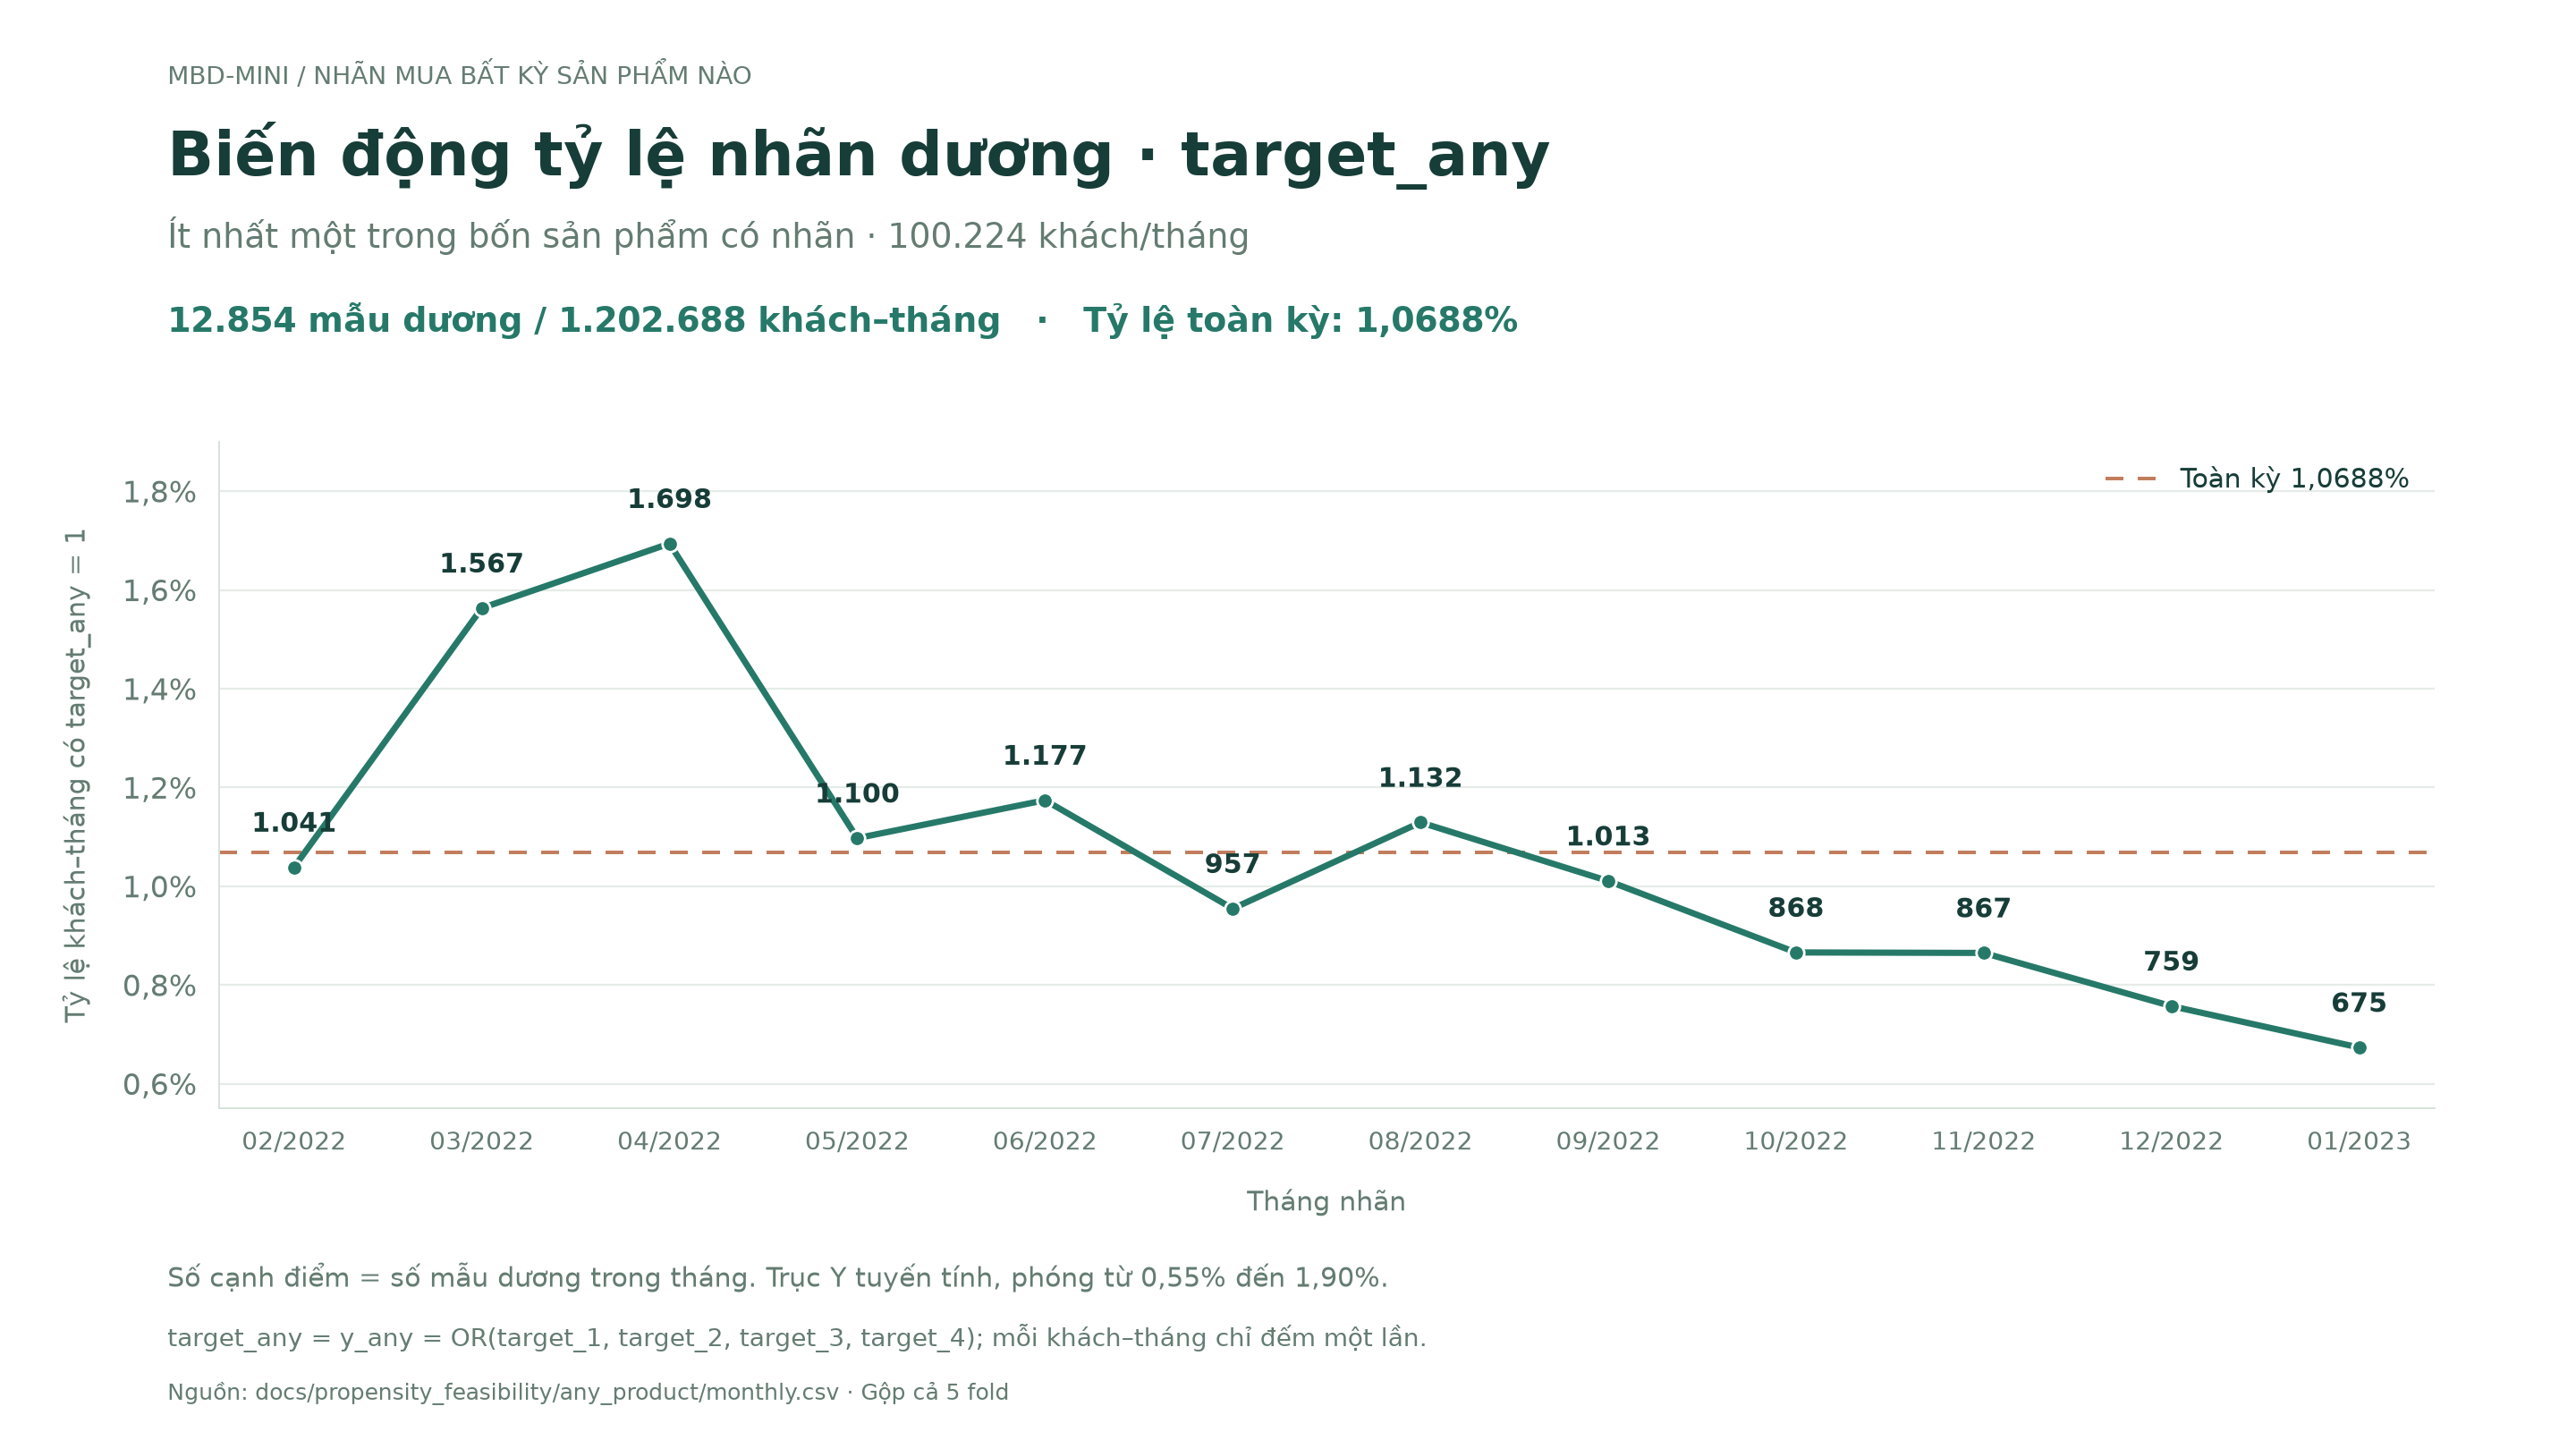

**outputs/full_population_temporal_eda_20261118/source_inventory.csv** — 5 dòng đầu

,source,raw_rows,first_event_moscow,last_event_moscow,first_month,last_month,first_month_partial
0,trx,38764930,2021-01-01 00:00:02.169545,2022-12-31 23:59:58.460193,2021-01-01,2022-12-01,False
1,geo,66295724,2021-12-11 22:27:07.507106,2022-12-31 23:59:58.725788,2021-12-01,2022-12-01,True
2,dialog,217205,2021-02-10 12:36:07.022271,2022-12-31 23:25:11.730797,2021-02-01,2022-12-01,True


File kết quả khác: `outputs/full_population_temporal_eda_20261118/all_customer_months.parquet`, `outputs/full_population_temporal_eda_20261118/labels_any.parquet`

In [7]:
show_generated_results(__eda_started_ns, 'src/plot_target_any.py')

## Analyze Target Focused Moscow

Nguồn: `src/scripts/analyze_target_focused_moscow.py`. Chạy các ô của phần này theo thứ tự.

In [8]:
__file__ = str(ROOT / 'src/scripts/analyze_target_focused_moscow.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [9]:
"""Target-first, full-population EDA from Moscow-month raw-log aggregates."""
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[2]
BASE = ROOT / 'outputs/full_population_temporal_eda_20261118'
OUT = ROOT / 'outputs/target_focused_moscow_20261119'
OUT.mkdir(exist_ok=True)
c = duckdb.connect()
c.execute("SET memory_limit='4GB'")
c.execute("SET threads=2")
c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp'")
c.execute(f"CREATE VIEW p AS SELECT * FROM read_parquet('{(BASE/'all_customer_months.parquet').as_posix()}')")
# Complete history through the previous Moscow calendar month; source absence is explicit.
q = """
WITH h AS (
 SELECT client_id, month, y,
  sum(coalesce(trx_events,0)) OVER w AS trx_hist,
  sum(coalesce(geo_events,0)) OVER w AS geo_hist,
  sum(coalesce(dialog_events,0)) OVER w AS dialog_hist,
  sum(coalesce(amount11,0)) OVER w AS amount11_hist,
  max(CASE WHEN trx_events>0 THEN month END) OVER w AS last_trx_month,
  max(CASE WHEN geo_events>0 THEN month END) OVER w AS last_geo_month,
  max(CASE WHEN dialog_events>0 THEN month END) OVER w AS last_dialog_month,
  lead(y,1) OVER (PARTITION BY client_id ORDER BY month) AS y2,
  lead(y,2) OVER (PARTITION BY client_id ORDER BY month) AS y3
 FROM p WINDOW w AS (PARTITION BY client_id ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
)
SELECT *, date_diff('month',last_trx_month,month) AS trx_recency_months,
 date_diff('month',last_geo_month,month) AS geo_recency_months,
 date_diff('month',last_dialog_month,month) AS dialog_recency_months
FROM h WHERE y IS NOT NULL AND y2 IS NOT NULL AND y3 IS NOT NULL
"""
d = c.execute(q).df()
d['y1'] = d.y.astype('int8')
d['yh2'] = (d.y1 | d.y2.astype('int8'))
d['yh3'] = (d.yh2 | d.y3.astype('int8'))
# Raw target labels remain on their original Moscow calendar month; mon is a
# month identifier and must not be timezone shifted.
target_path=(ROOT/'data/MBD-mini/targets/**/*.parquet').as_posix()
products=c.execute(f"SELECT client_id, date_trunc('month',cast(mon AS DATE)) AS \"month\", target_1,target_2,target_3,target_4 FROM read_parquet('{target_path}')").df()
assert not products.duplicated(['client_id','month']).any()
d=d.merge(products,on=['client_id','month'],how='left',validate='one_to_one')
assert d[[f'target_{i}' for i in range(1,5)]].notna().all().all()
n_clients = d.client_id.nunique()
n_months = d.month.nunique()
assert len(d) == n_clients*n_months and n_months == 10
assert d.groupby('month').client_id.nunique().eq(n_clients).all()
assert (d[['y1','yh2','yh3']].sum(axis=0).diff().dropna() >= 0).all()

rows=[]
def add(feature, band, mask):
    z=d.loc[mask]
    row={'feature':feature,'group':band,'n':len(z),'customers':z.client_id.nunique()}
    for h in (1,2,3):
        row[f'buyers_h{h}']=int(z[f'yh{h}' if h>1 else 'y1'].sum())
        row[f'rate_h{h}']=row[f'buyers_h{h}']/len(z) if len(z) else np.nan
    rows.append(row)

for col in ['trx_hist','geo_hist','dialog_hist']:
    x=d[col].fillna(0)
    groups=[('0',x.eq(0)),('1–9',x.between(1,9)),('10–99',x.between(10,99)),('100+',x.ge(100))]
    assert sum(int(m.sum()) for _,m in groups)==len(d)
    for name,mask in groups:add(col,name,mask)
for col in ['trx_recency_months','geo_recency_months','dialog_recency_months']:
    x=d[col]
    groups=[('no prior log',x.isna()),('previous month',x.eq(1)),('2–3 months',x.between(2,3)),('4+ months',x.ge(4))]
    assert sum(int(m.sum()) for _,m in groups)==len(d)
    for name,mask in groups:add(col,name,mask)
presence=(d[['trx_hist','geo_hist','dialog_hist']].fillna(0)>0).sum(axis=1)
for k in range(4):add('number_of_sources',str(k),presence.eq(k))
rates=pd.DataFrame(rows)
base={h:float(d[f'yh{h}' if h>1 else 'y1'].mean()) for h in (1,2,3)}
for h in (1,2,3):rates[f'lift_h{h}']=rates[f'rate_h{h}']/base[h]
rates.to_csv(OUT/'target_group_rates.csv',index=False)

# Check nonlinear threshold and rank association on the same rows, without sampling.
assoc=[]
for col in ['trx_hist','geo_hist','dialog_hist','amount11_hist']:
    x=np.log1p(d[col].fillna(0).clip(lower=0))
    for h in (1,2,3):
        y=d[f'yh{h}' if h>1 else 'y1']
        assoc.append({'feature':col,'horizon':h,'pearson_log1p':x.corr(y),
                      'spearman':d[col].fillna(0).corr(y,method='spearman')})
pd.DataFrame(assoc).to_csv(OUT/'global_associations.csv',index=False)
month=d.groupby('month').agg(n=('client_id','size'),buyers_h1=('y1','sum'),buyers_h2=('yh2','sum'),buyers_h3=('yh3','sum')).reset_index()
for h in (1,2,3):month[f'rate_h{h}']=month[f'buyers_h{h}']/month.n
month.to_csv(OUT/'monthly_baseline.csv',index=False)
# Hypothesis checks that keep all rows in exhaustive, mutually exclusive groups.
d['dialog_recent'] = d.dialog_recency_months.eq(1).fillna(False)
d['trx_state'] = np.select([d.trx_hist.fillna(0).eq(0),d.trx_recency_months.eq(1).fillna(False)],
                           ['no history','active previous month'],default='older history')
d['geo_state'] = np.select([d.geo_hist.fillna(0).eq(0),d.geo_recency_months.eq(1).fillna(False)],
                           ['no history','active previous month'],default='older history')
def grouped(frame, keys, filename):
    z=frame.groupby(keys,dropna=False,observed=True).agg(n=('y1','size'),buyers_h1=('y1','sum'),
        buyers_h2=('yh2','sum'),buyers_h3=('yh3','sum')).reset_index()
    assert z.n.sum()==len(frame)
    for h in (1,2,3):
        z[f'rate_h{h}']=z[f'buyers_h{h}']/z.n
        z[f'lift_h{h}']=z[f'rate_h{h}']/base[h]
    z.to_csv(OUT/filename,index=False)
    return z
interaction=grouped(d,['trx_state','dialog_recent'],'dialog_by_trx_state.csv')
geo_interaction=grouped(d,['geo_state','dialog_recent'],'dialog_by_geo_state.csv')

In [10]:
monthly_dialog=grouped(d,['month','dialog_recent'],'dialog_by_month.csv')
d['trx_band']=pd.cut(d.trx_hist.fillna(0),[-1,0,9,99,np.inf],labels=['0','1-9','10-99','100+'])
d['geo_band']=pd.cut(d.geo_hist.fillna(0),[-1,0,9,99,np.inf],labels=['0','1-9','10-99','100+'])
trx_geo=grouped(d,['trx_band','geo_band'],'trx_geo_interaction.csv')
# Currency 11 monetary values are not mixed with other currencies. Negative
# cumulative sums are retained as their own state rather than clipped to zero.
a=d.amount11_hist.fillna(0)
d['amount11_band']=np.select([a.lt(0),a.eq(0),a.between(0,1e5,inclusive='neither'),
                              a.between(1e5,1e7,inclusive='both'),a.gt(1e7)],
                             ['negative','zero','(0,100k)','100k-10m','>10m'],default='unclassified')
amount=grouped(d,['amount11_band'],'amount11_target.csv')
# Association among predictors helps identify overlapping signals.
pred=np.log1p(d[['trx_hist','geo_hist','dialog_hist']].fillna(0).clip(lower=0))
pred.corr(method='spearman').to_csv(OUT/'predictor_rank_correlations.csv')
# Product-specific associations, preserving customers with multiple products.
def product_table(keys, filename):
    z=d.groupby(keys,dropna=False,observed=True).agg(n=('y1','size'),
        **{f'buyers_p{i}':(f'target_{i}','sum') for i in range(1,5)}).reset_index()
    assert z.n.sum()==len(d)
    for i in range(1,5):z[f'rate_p{i}']=z[f'buyers_p{i}']/z.n
    z.to_csv(OUT/filename,index=False)
    return z
product_rates=product_table(['dialog_recent'],'dialog_by_product.csv')
product_table(['trx_state','dialog_recent'],'dialog_trx_by_product.csv')
product_table(['month','dialog_recent'],'dialog_product_by_month.csv')
# Previous observed target months are known at cutoff; the first label month
# has unknown purchase history and is retained in a separate group.
prior=c.execute(f"""
 SELECT client_id,month,
  sum(y) OVER (PARTITION BY client_id ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) prior_observed_buy_months
 FROM read_parquet('{(BASE/'labels_any.parquet').as_posix()}')
""").df()
d=d.merge(prior,on=['client_id','month'],how='left',validate='one_to_one')
d['prior_purchase_state']=np.select([d.prior_observed_buy_months.isna(),d.prior_observed_buy_months.eq(0).fillna(False)],
    ['unknown before label start','no observed prior purchase'],default='observed prior purchase')
grouped(d,['prior_purchase_state','dialog_recent'],'dialog_by_prior_purchase.csv')
fig,ax=plt.subplots(figsize=(8,4.5))
xs=np.arange(4)
for flag,offset,color,label in [(False,-.18,'#94a3b8','No DIALOG previous month'),
                                (True,.18,'#0f766e','DIALOG previous month')]:
    z=product_rates[product_rates.dialog_recent.eq(flag)].iloc[0]
    ax.bar(xs+offset,[z[f'rate_p{i}']*100 for i in range(1,5)],width=.36,color=color,label=label)
ax.set_xticks(xs,[f'Product {i}' for i in range(1,5)])
ax.set_ylabel('Purchased in next month (%)');ax.set_title('DIALOG association by product')
ax.legend(frameon=False);fig.tight_layout();fig.savefig(OUT/'dialog_product_rates.png',dpi=170);plt.close(fig)
fig,ax=plt.subplots(figsize=(8,4.5))
order=['no history','older history','active previous month']
for flag,color,label in [(False,'#94a3b8','No DIALOG previous month'),
                         (True,'#0f766e','DIALOG previous month')]:
    z=interaction[interaction.dialog_recent.eq(flag)].set_index('trx_state').loc[order]
    ax.plot(order,z.rate_h1*100,marker='o',linewidth=2,color=color,label=label)
ax.set_ylabel('Purchased in next month (%)');ax.set_title('DIALOG association within TRX states')
ax.legend(frameon=False);ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUT/'dialog_trx_interaction.png',dpi=170);plt.close(fig)
fig,ax=plt.subplots(figsize=(9,4.5))
for state,part in monthly_dialog.groupby('dialog_recent'):
    ax.plot(part.month,part.rate_h1*100,marker='o',label='DIALOG previous month' if state else 'Other customers')
ax.set_ylabel('Purchased in next month (%)');ax.set_title('DIALOG relationship by cutoff month')
ax.legend(frameon=False);ax.grid(alpha=.2);fig.autofmt_xdate();fig.tight_layout()
fig.savefig(OUT/'dialog_monthly_stability.png',dpi=170);plt.close(fig)
fig,ax=plt.subplots(figsize=(9,4.5))
v=rates[rates.feature.eq('dialog_recency_months')]
labels=['No prior log','Previous month','2-3 months','4+ months']
ax.bar(labels,v.rate_h1.to_numpy()*100,color=['#94a3b8','#0f766e','#5ba69d','#a5cbc6'])
ax.axhline(base[1]*100,color='#b45309',linestyle='--',label=f'All customers: {base[1]*100:.2f}%')
for i,row in enumerate(v.itertuples()):ax.text(i,row.rate_h1*100+.12,f'{row.rate_h1*100:.2f}%\nn={row.n:,}',ha='center',fontsize=9)
ax.set_ylim(0,5.3);ax.set_ylabel('Purchased in next month (%)');ax.set_title('Prior DIALOG activity and next-month purchase')
ax.legend(frameon=False);fig.tight_layout();fig.savefig(OUT/'dialog_recency_target.png',dpi=170);plt.close(fig)
fig,ax=plt.subplots(figsize=(9,4.5))
v=rates[rates.feature.eq('trx_hist')]
ax.bar(['0','1-9','10-99','100+'],v.rate_h1.to_numpy()*100,color='#2563eb')
ax.axhline(base[1]*100,color='#b45309',linestyle='--',label=f'All customers: {base[1]*100:.2f}%')
for i,row in enumerate(v.itertuples()):ax.text(i,row.rate_h1*100+.05,f'{row.rate_h1*100:.2f}%\nn={row.n:,}',ha='center',fontsize=9)
ax.set_ylim(0,2);ax.set_ylabel('Purchased in next month (%)');ax.set_xlabel('All prior TRX events');ax.set_title('TRX relationship is non-monotonic')
ax.legend(frameon=False);fig.tight_layout();fig.savefig(OUT/'trx_threshold_target.png',dpi=170);plt.close(fig)
print('cohort',n_clients,n_months,len(d),'baseline',base)
print(rates[['feature','group','n','rate_h1','lift_h1','rate_h2','lift_h2','rate_h3','lift_h3']].to_string(index=False))
print(pd.DataFrame(assoc).to_string(index=False))

cohort 100224 10 1002240 baseline {1: 0.011394476372924648, 2: 0.021684426883780333, 3: 0.030680276181353768}
              feature          group      n  rate_h1  lift_h1  rate_h2  lift_h2  rate_h3  lift_h3
             trx_hist              0  84670 0.014055 1.233454 0.031747 1.464036 0.049569 1.615661
             trx_hist            1–9 101092 0.007617 0.668466 0.012434 0.573417 0.016074 0.523935
             trx_hist          10–99 296569 0.005867 0.514907 0.010881 0.501794 0.015241 0.496768
             trx_hist           100+ 519909 0.014849 1.303154 0.028007 1.291564 0.039251 1.279359
             geo_hist              0 338518 0.009075 0.796425 0.017455 0.804978 0.024953 0.813320
             geo_hist            1–9  53045 0.011556 1.014195 0.022471 1.036296 0.031803 1.036600
             geo_hist          10–99 184269 0.012368 1.085420 0.024149 1.113678 0.034287 1.117553
             geo_hist           100+ 426408 0.012795 1.122935 0.023879 1.101184 0.033529 1.092849
        

### Kết quả: `src/scripts/analyze_target_focused_moscow.py`

**outputs/full_population_temporal_eda_20261118/01_full_calendar_inventory.png**

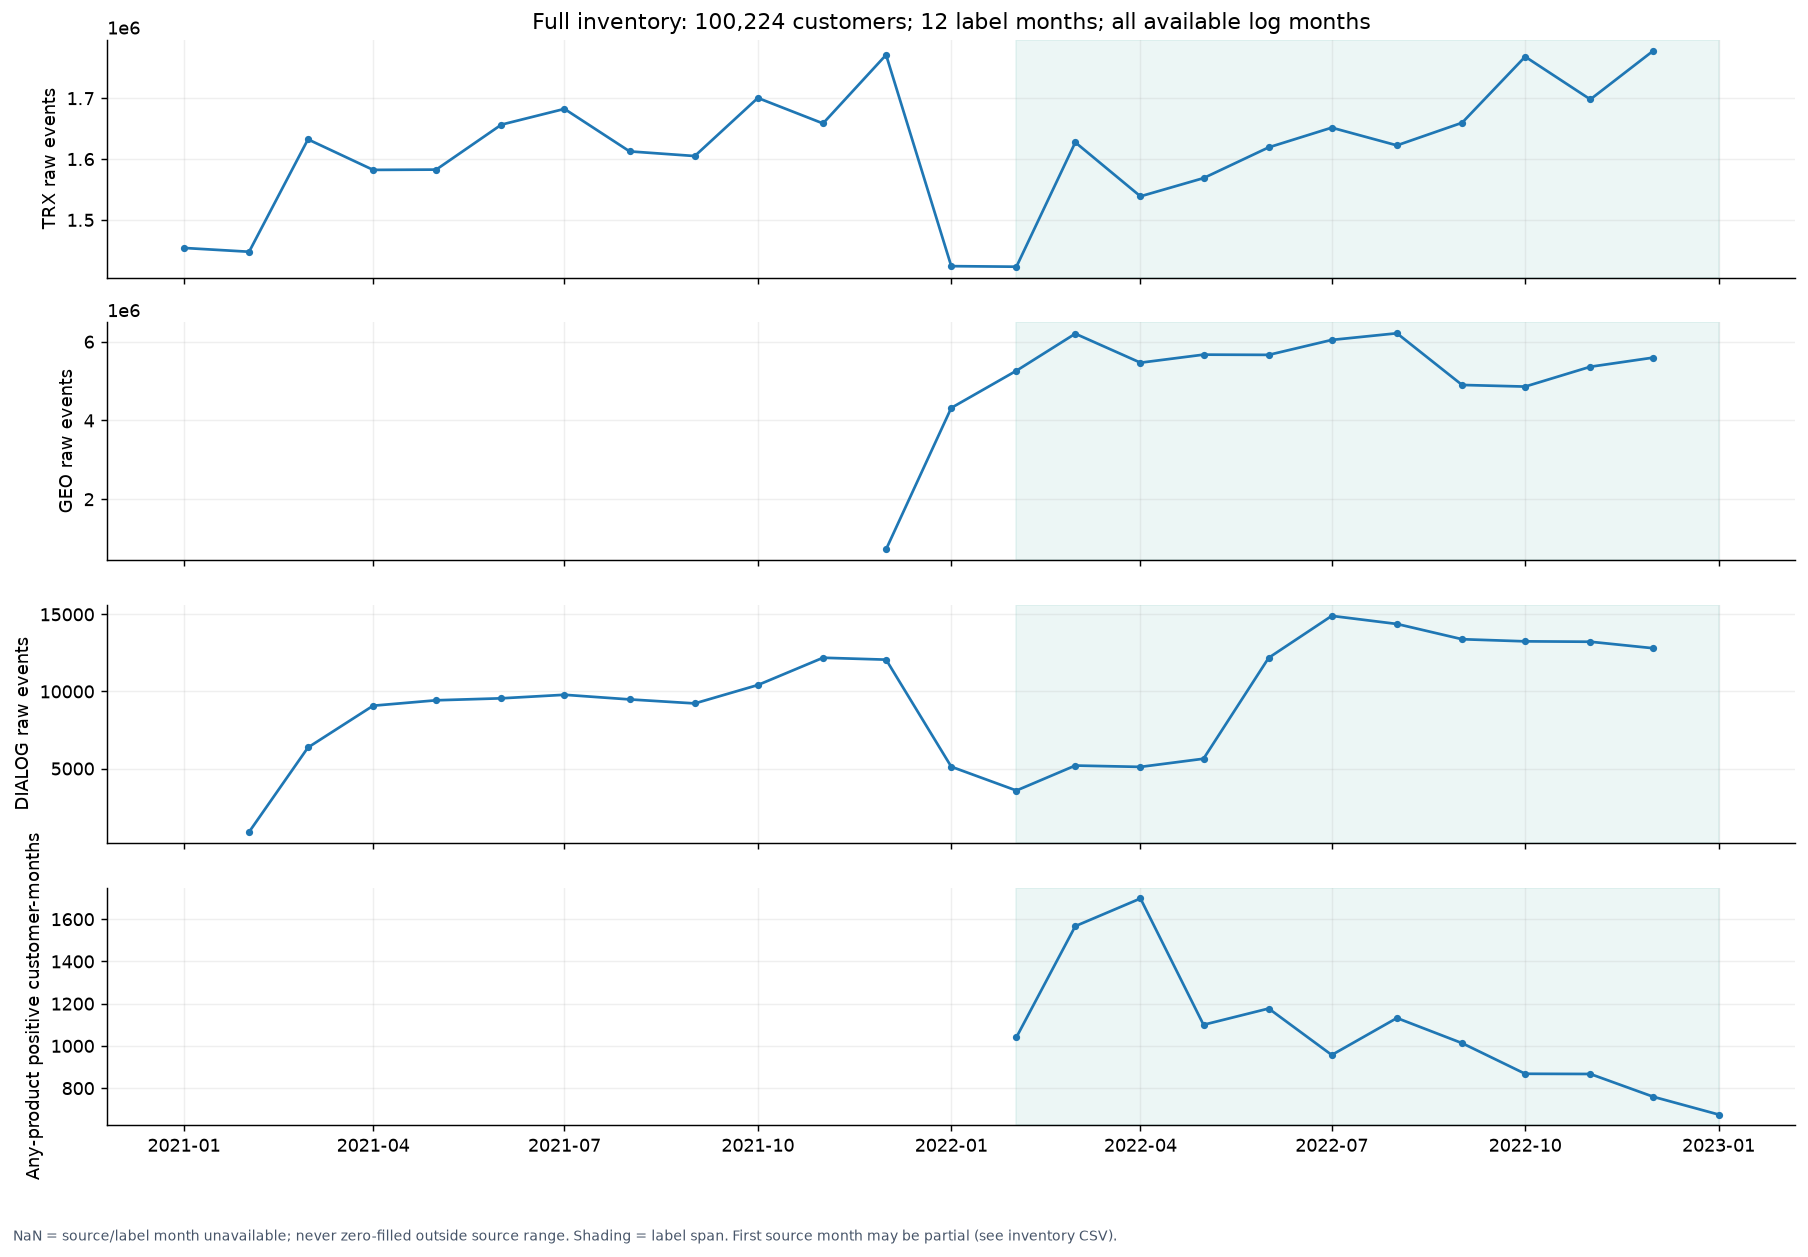

**outputs/full_population_temporal_eda_20261118/02_exhaustive_monthly_groups.png**

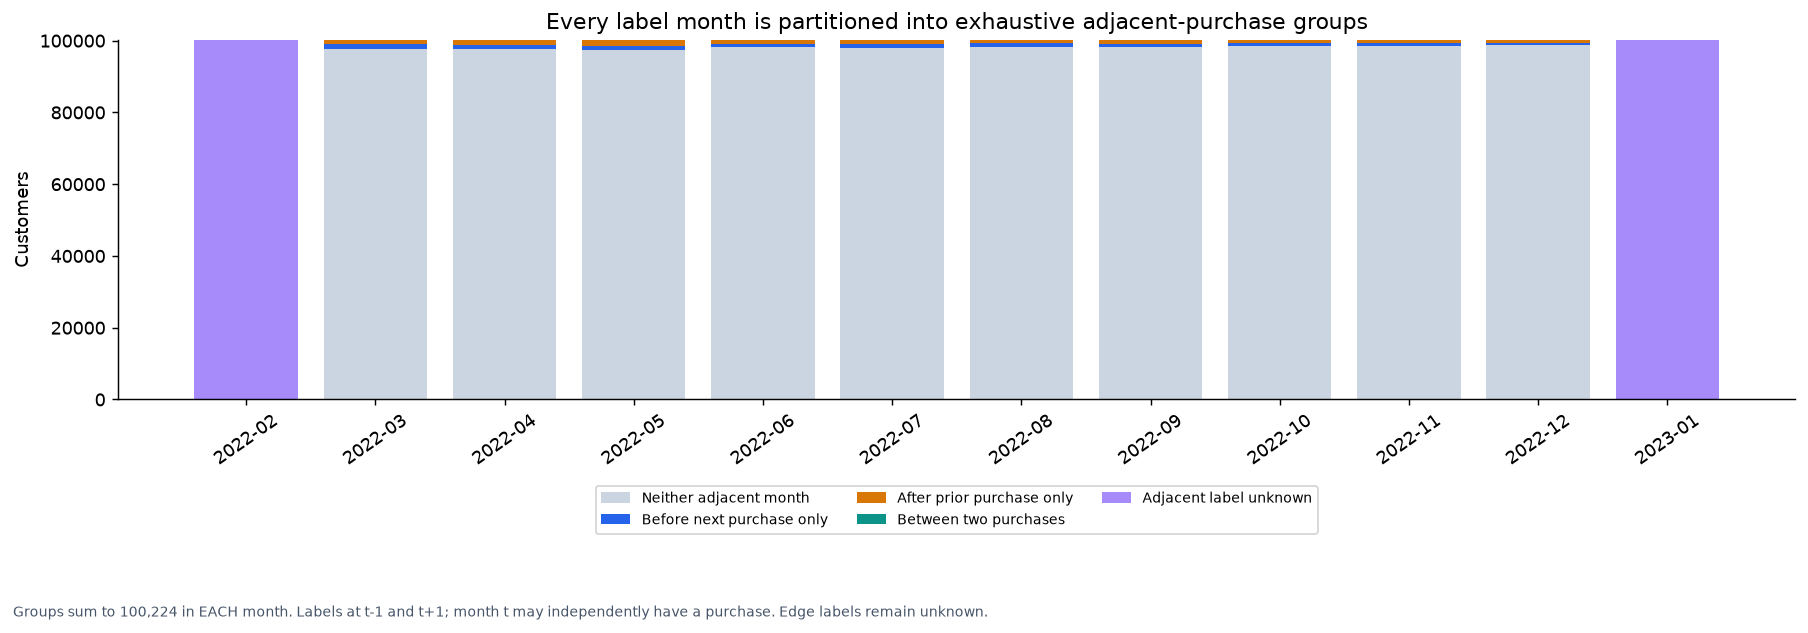

**outputs/full_population_temporal_eda_20261118/03_before_vs_after_all_label_months.png**

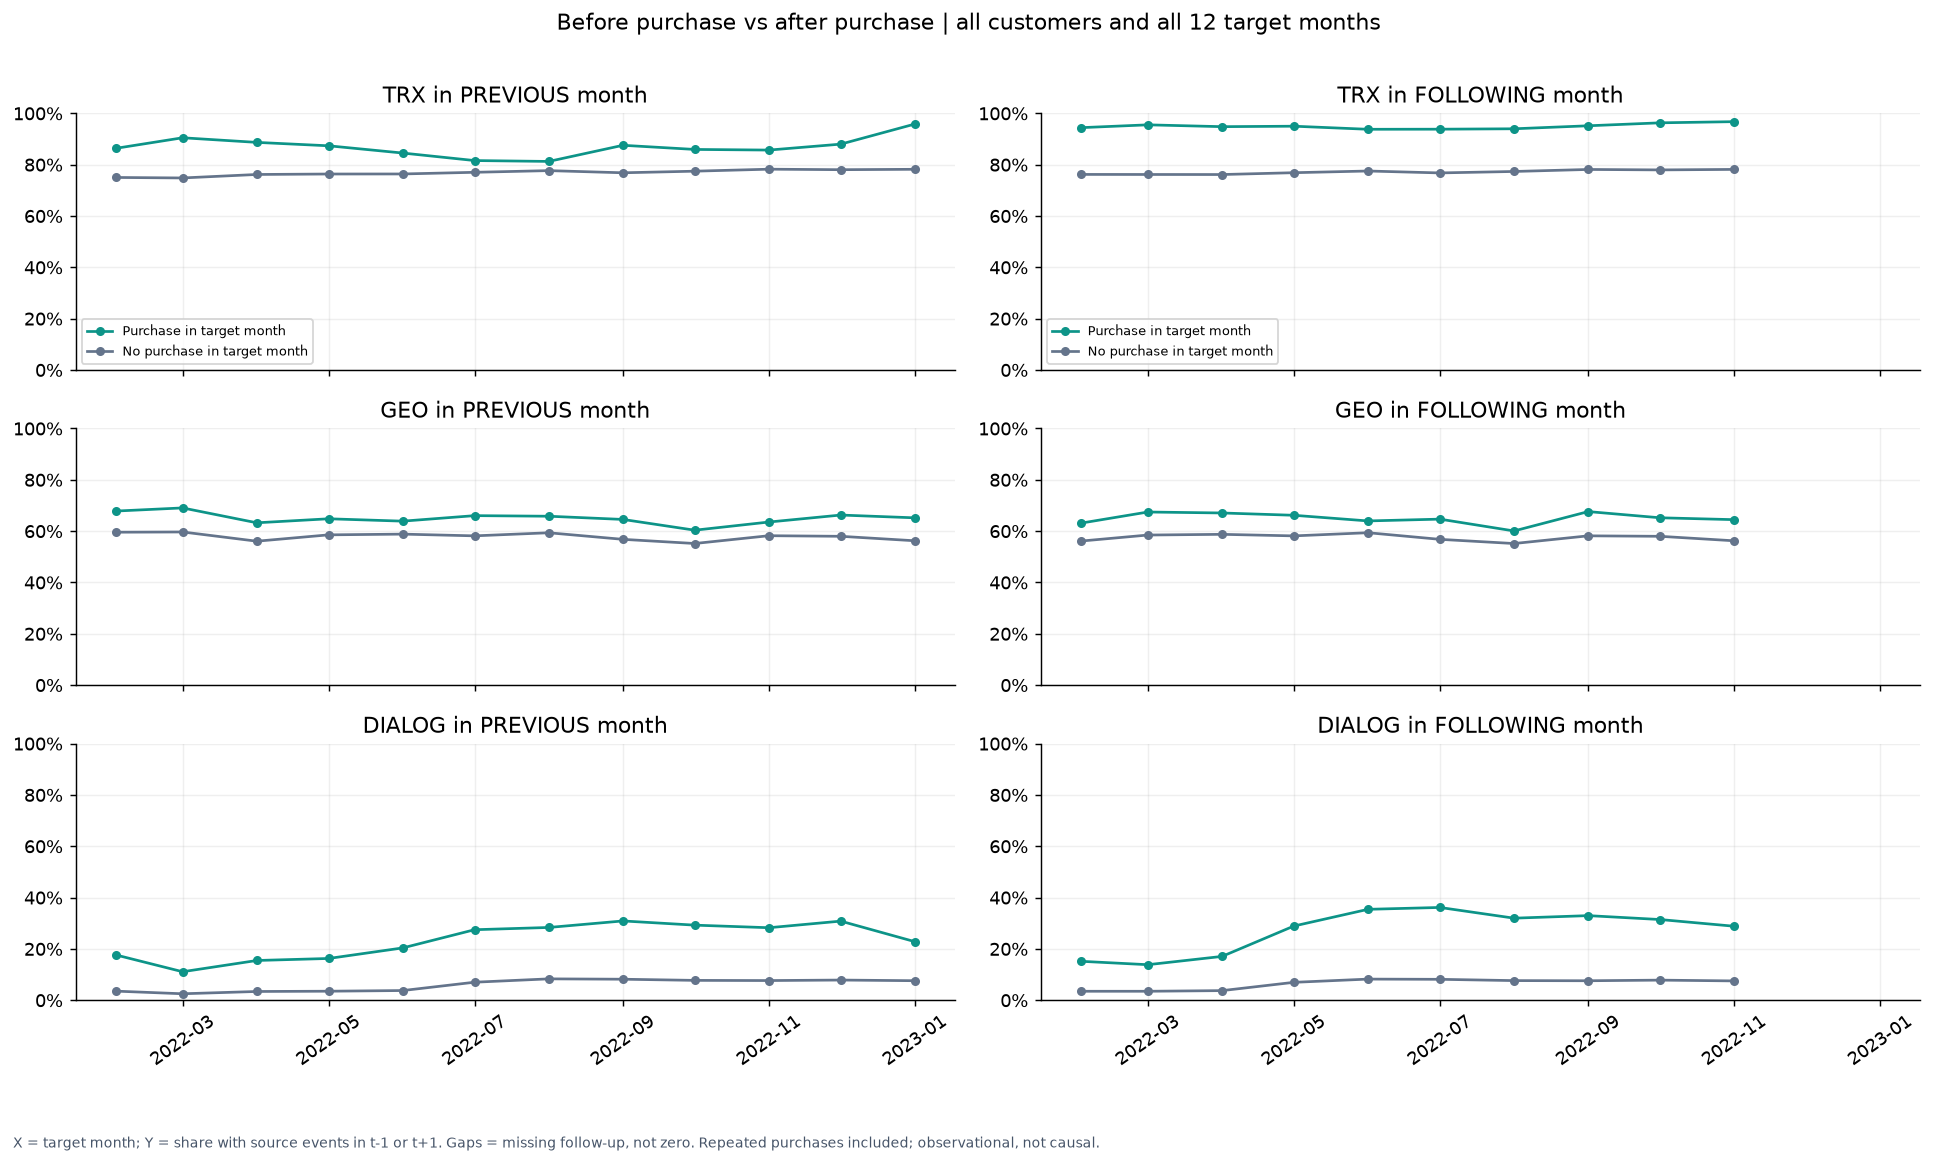

**outputs/full_population_temporal_eda_20261118/04_prior_next_purchase_groups.png**

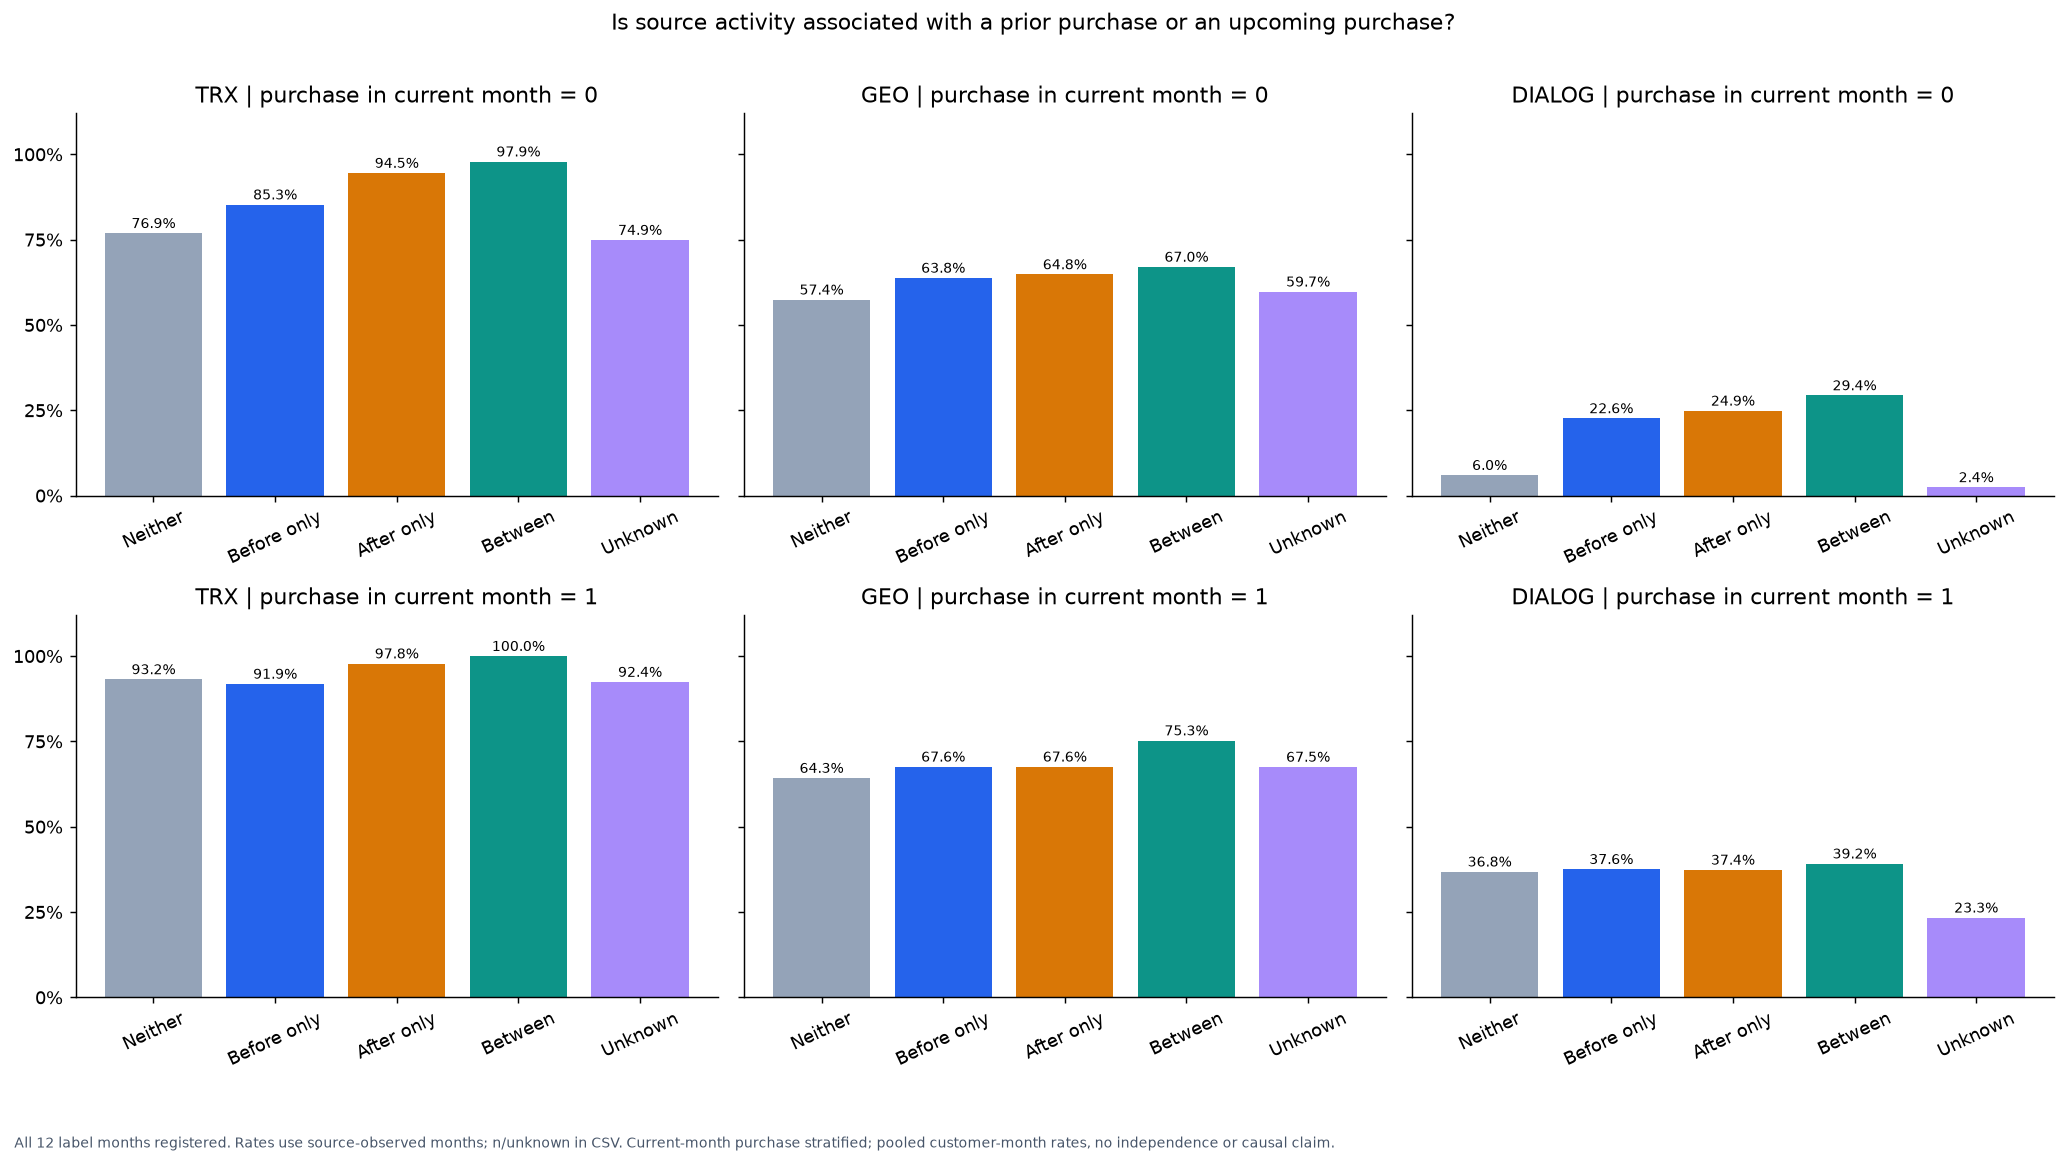

**outputs/full_population_temporal_eda_20261118/05_full_history_financial_contribution.png**

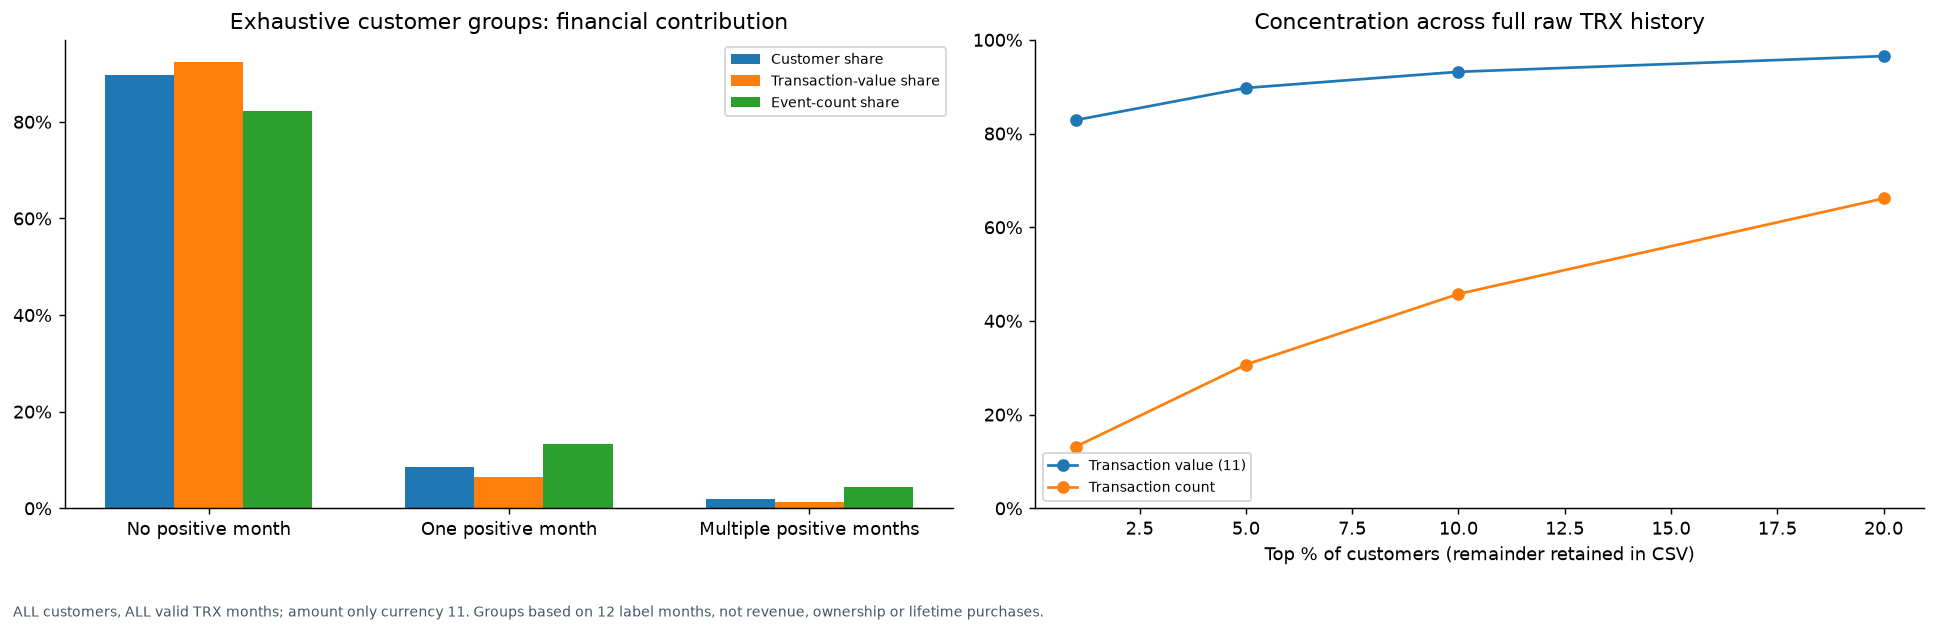

**outputs/full_population_temporal_eda_20261118/06_full_population_source_order.png**

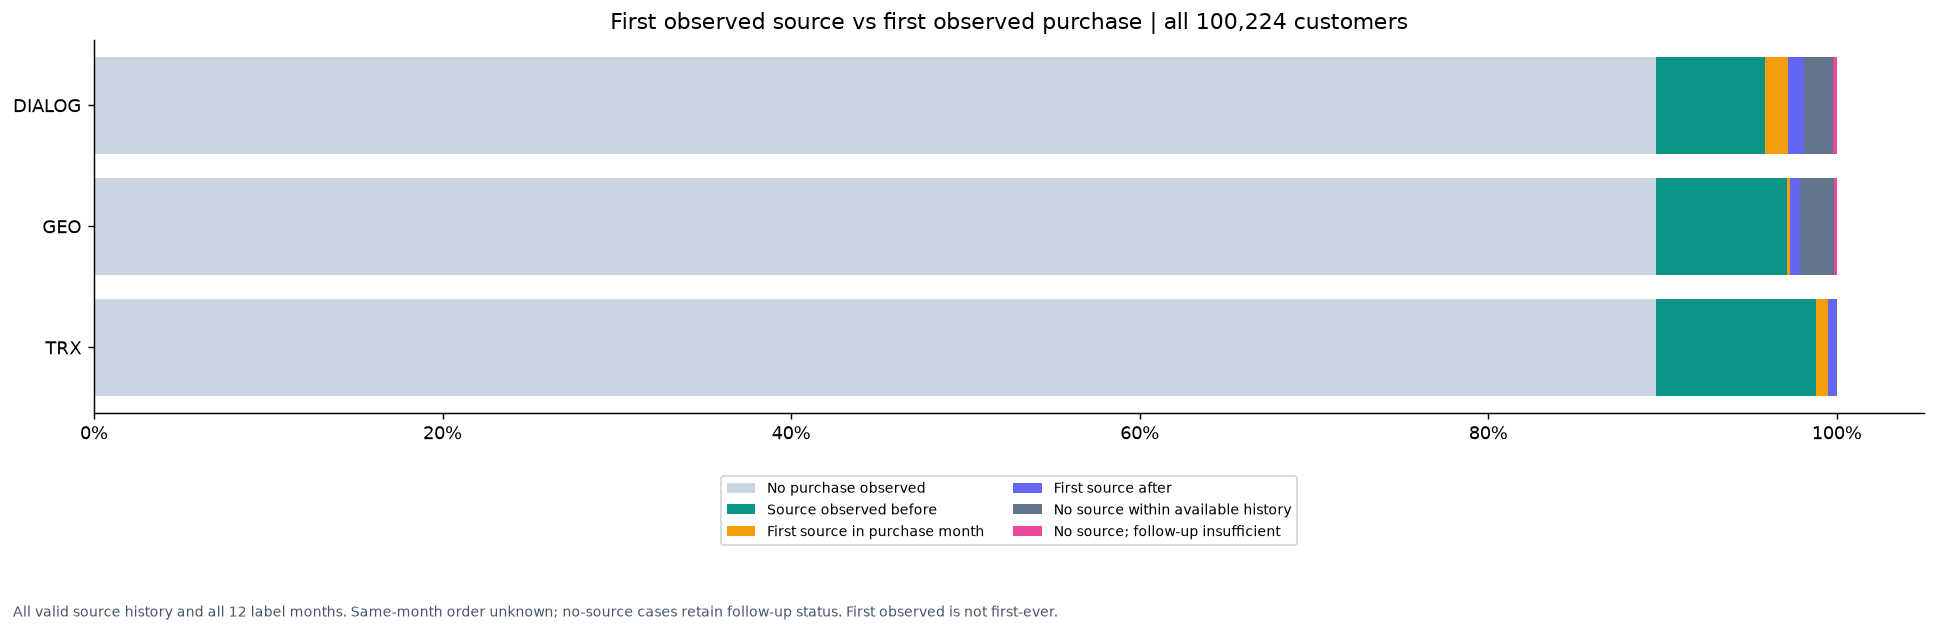

**outputs/target_focused_moscow_20261119/dialog_monthly_stability.png**

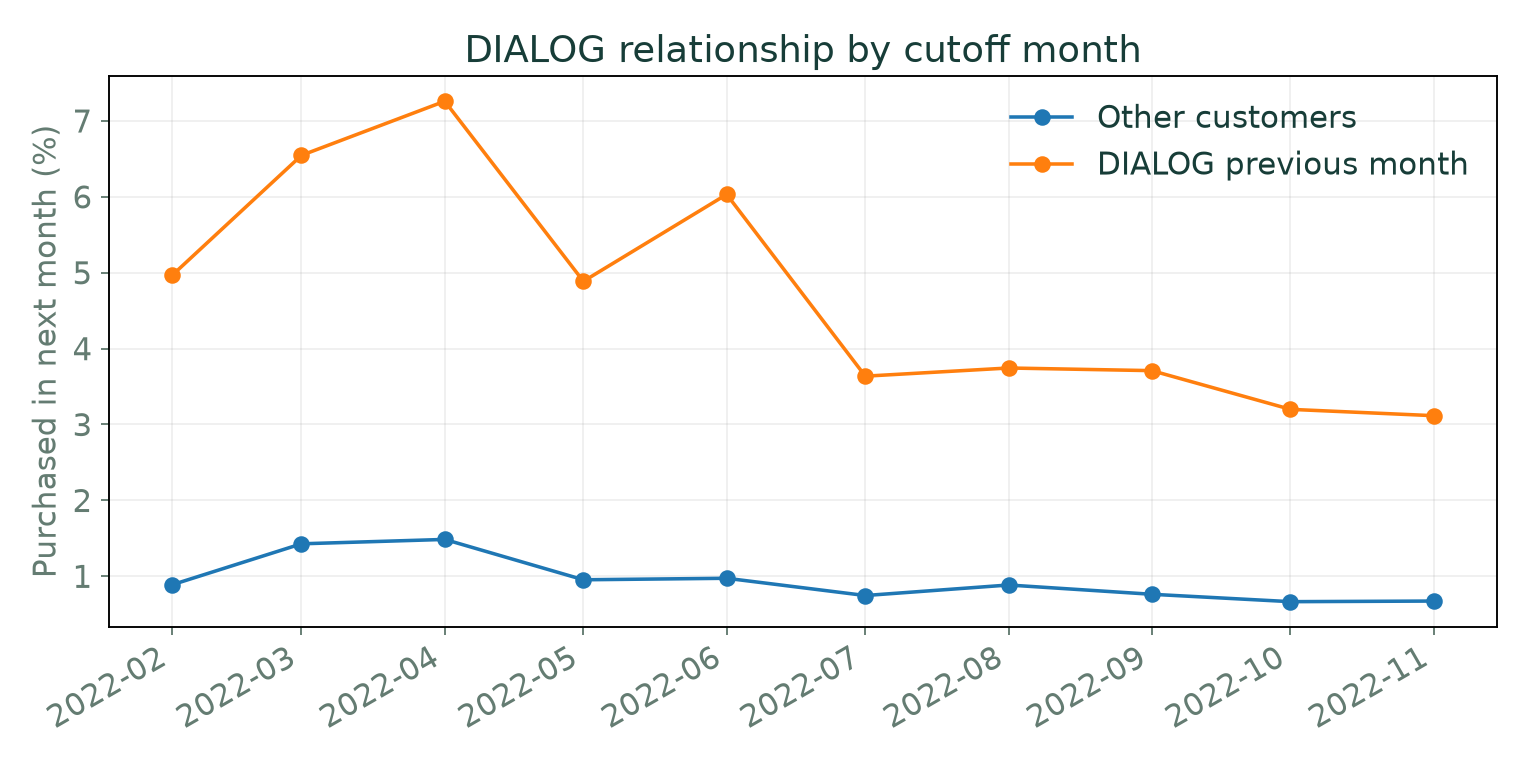

**outputs/target_focused_moscow_20261119/dialog_product_rates.png**

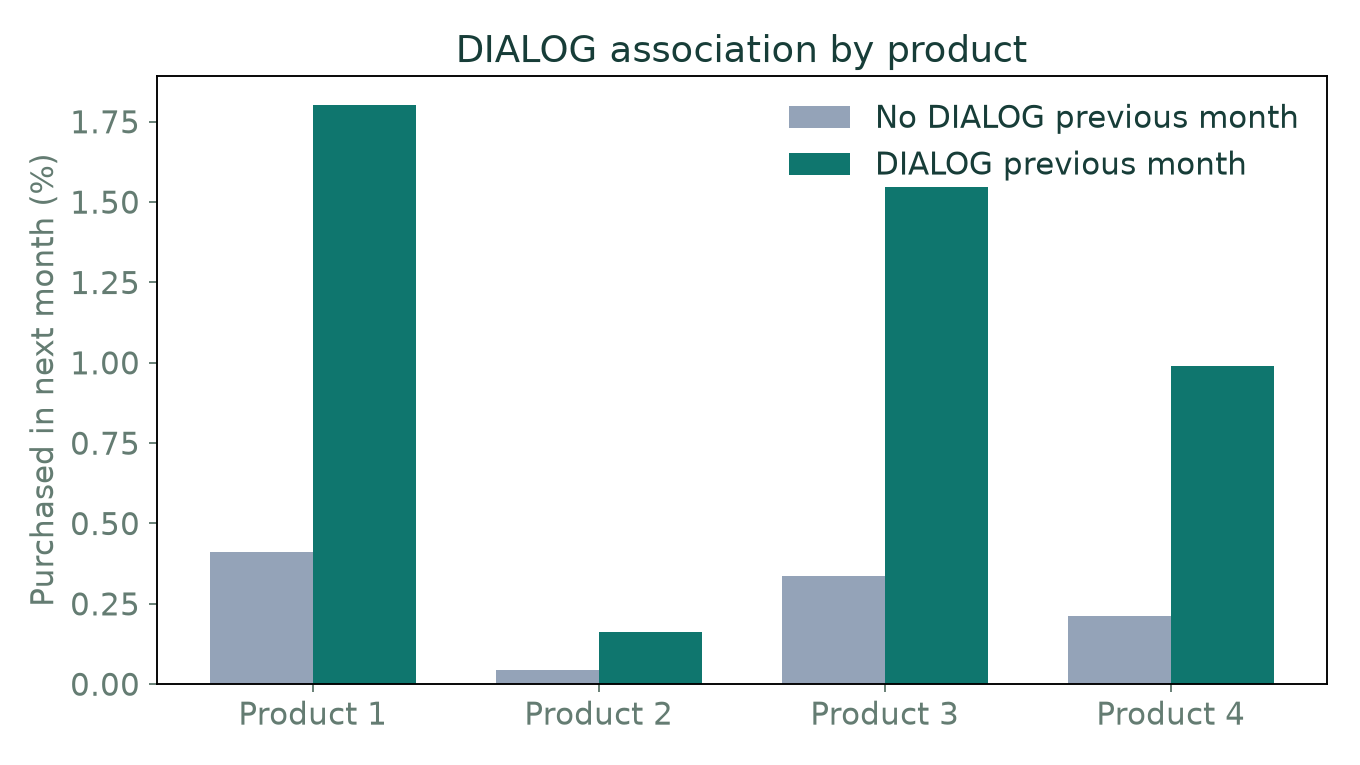

**outputs/target_focused_moscow_20261119/dialog_recency_target.png**

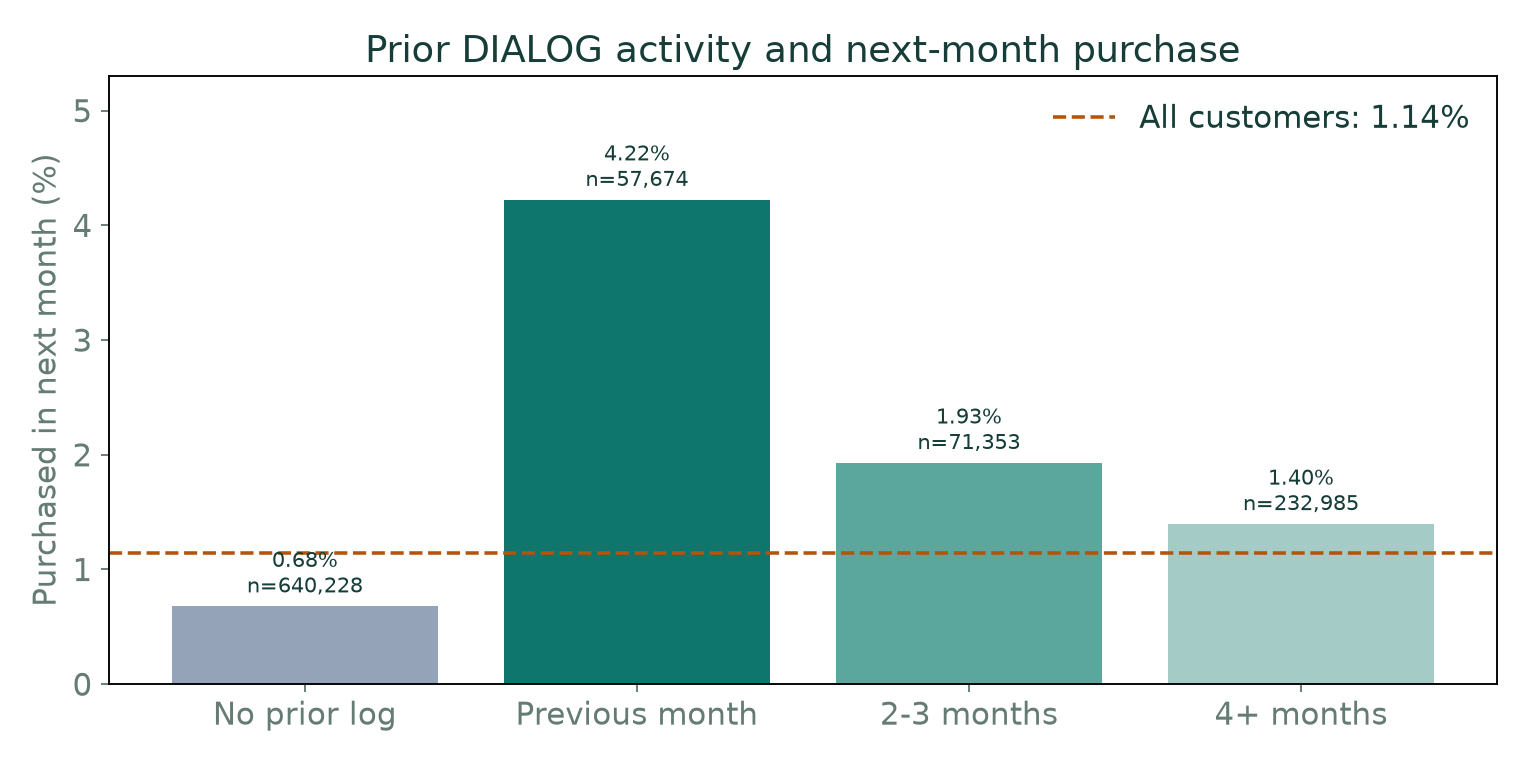

**outputs/target_focused_moscow_20261119/dialog_trx_interaction.png**

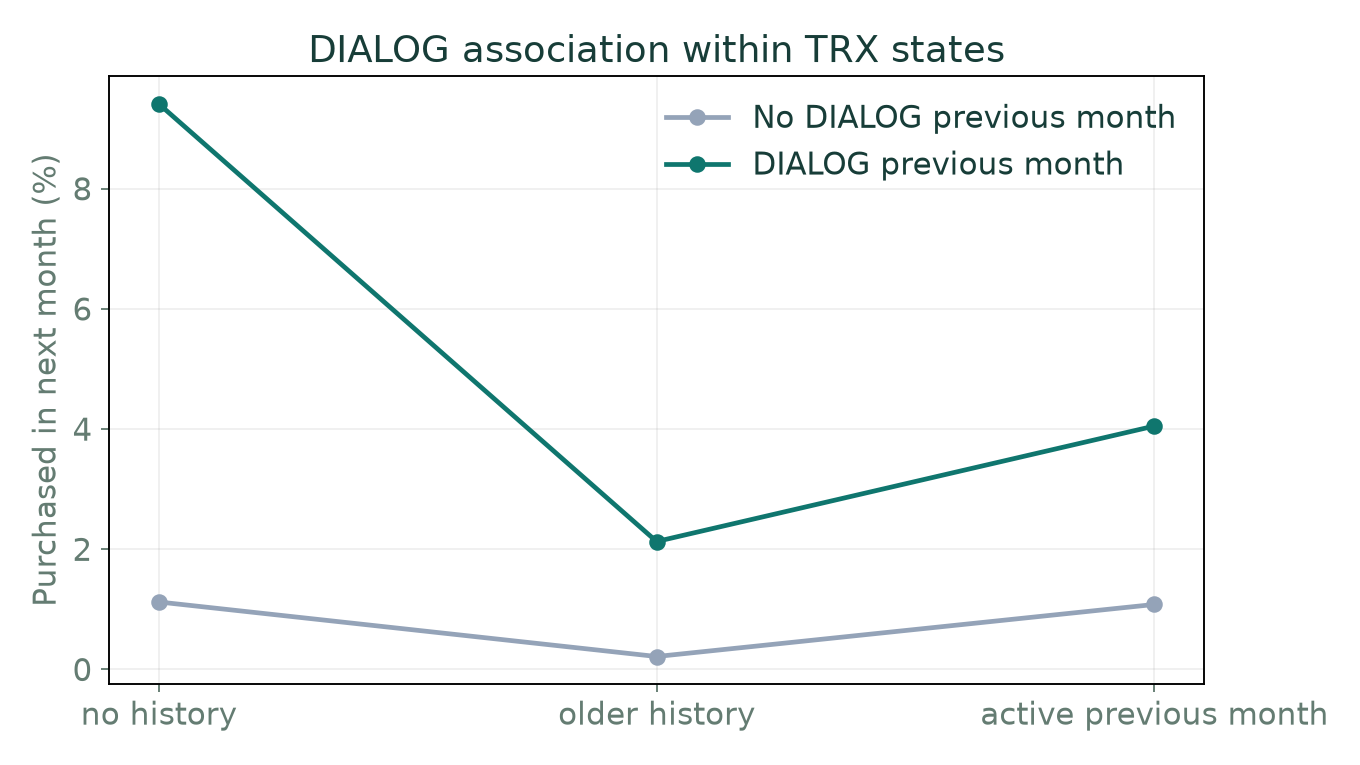

**outputs/target_focused_moscow_20261119/trx_threshold_target.png**

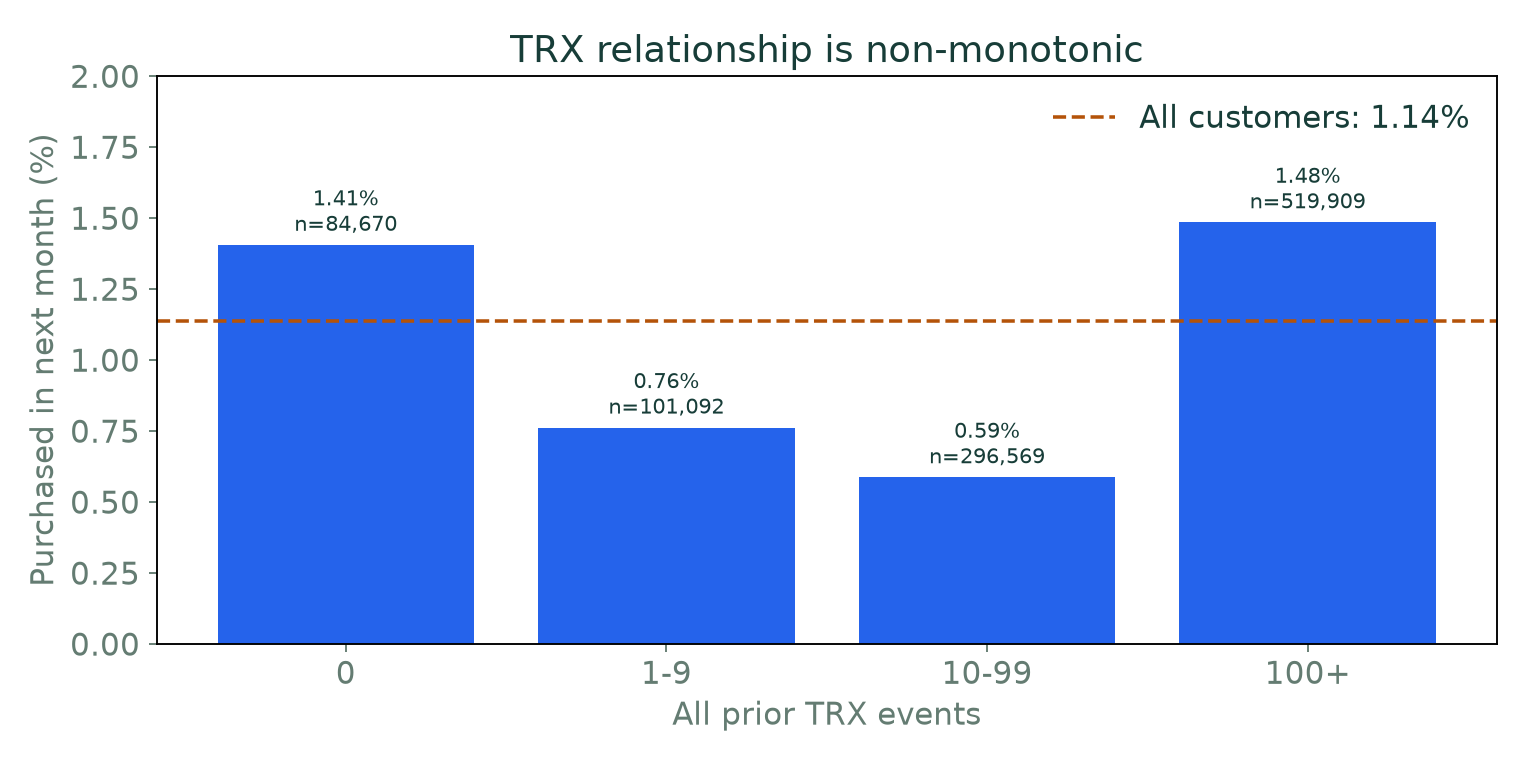

**outputs/full_population_temporal_eda_20261118/adjacent_purchase_source_associations.csv** — 5 dòng đầu

,state,current_purchase,source,total_customer_months,observed_customer_months,unavailable_customer_months,active,rate
0,Adjacent label unknown,0,trx,198732,99183,99549,74281,0.748929
1,Adjacent label unknown,0,geo,198732,99183,99549,59256,0.597441
2,Adjacent label unknown,0,dialog,198732,99183,99549,2415,0.024349
3,Adjacent label unknown,1,trx,1716,1041,675,962,0.924111
4,Adjacent label unknown,1,geo,1716,1041,675,703,0.675312


**outputs/full_population_temporal_eda_20261118/before_after_monthly_rate_ratios.csv** — 5 dòng đầu

,target_month,lag,source,nonbuyer_rate,buyer_rate,rate_ratio
0,2022-02-01,-1,dialog,0.035510,0.176753,4.977543
1,2022-02-01,-1,geo,0.595828,0.678194,1.138238
2,2022-02-01,-1,trx,0.750219,0.863593,1.151120
3,2022-02-01,1,dialog,0.034935,0.151777,4.344506
4,2022-02-01,1,geo,0.561286,0.631124,1.124425


**outputs/full_population_temporal_eda_20261118/before_after_monthly_rates.csv** — 5 dòng đầu

,target_month,lag,purchase,source,total_customers,observed_customers,unavailable_customers,active_customers,rate
0,2022-02-01,-1,0,trx,99183,99183,0,74409,0.750219
1,2022-02-01,-1,0,geo,99183,99183,0,59096,0.595828
2,2022-02-01,-1,0,dialog,99183,99183,0,3522,0.035510
3,2022-02-01,-1,1,trx,1041,1041,0,899,0.863593
4,2022-02-01,-1,1,geo,1041,1041,0,706,0.678194


... (33 outputs left out)

,feature,group,n,customers,buyers_h1,rate_h1,buyers_h2,rate_h2,buyers_h3,rate_h3,lift_h1,lift_h2,lift_h3
0,trx_hist,0,84670,13224,1190,0.014055,2688,0.031747,4197,0.049569,1.233454,1.464036,1.615661
1,trx_hist,1–9,101092,19160,770,0.007617,1257,0.012434,1625,0.016074,0.668466,0.573417,0.523935
2,trx_hist,10–99,296569,40269,1740,0.005867,3227,0.010881,4520,0.015241,0.514907,0.501794,0.496768
3,trx_hist,100+,519909,57409,7720,0.014849,14561,0.028007,20407,0.039251,1.303154,1.291564,1.279359
4,geo_hist,0,338518,40187,3072,0.009075,5909,0.017455,8447,0.024953,0.796425,0.804978,0.813320


**outputs/target_focused_moscow_20261119/trx_geo_interaction.csv** — 5 dòng đầu

,trx_band,geo_band,n,buyers_h1,buyers_h2,buyers_h3,rate_h1,lift_h1,rate_h2,lift_h2,rate_h3,lift_h3
0,0,0,35300,438,985,1532,0.012408,1.088943,0.027904,1.286807,0.043399,1.414571
1,0,1-9,5189,79,160,238,0.015225,1.336131,0.030834,1.421963,0.045866,1.494975
2,0,10-99,15197,204,474,752,0.013424,1.178089,0.031190,1.438376,0.049483,1.612875
3,0,100+,28984,469,1069,1675,0.016181,1.420104,0.036882,1.700871,0.057791,1.883637
4,1-9,0,39438,237,377,486,0.006009,0.527399,0.009559,0.440837,0.012323,0.401663


File kết quả khác: `outputs/full_population_temporal_eda_20261118/all_customer_financial_groups.parquet`, `outputs/full_population_temporal_eda_20261118/label_month_panel_with_states.parquet`

In [11]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_target_focused_moscow.py')

## Targets

Nguồn: `src/mbd_mini_eda/descriptive/targets.py`. Chạy các ô của phần này theo thứ tự.

In [12]:
__file__ = str(ROOT / 'src/mbd_mini_eda/descriptive/targets.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = 'mbd_mini_eda.descriptive.targets'
__package__ = 'mbd_mini_eda.descriptive'


In [13]:
"""Bốn nhãn độc lập: tách tỷ lệ theo dòng và tỷ lệ theo khách."""
from itertools import combinations
import numpy as np
import pandas as pd
from ..schema import TARGET_COLUMNS
from ..statistics import result,target_rates

from ..models import AnalysisContext, SectionResult


def run(context: AnalysisContext) -> SectionResult:
    frame=context.artifacts["targets"]
    rows=[]
    for target in TARGET_COLUMNS:
        n=int(frame[target].notna().sum()); positive=int(frame[target].eq(1).sum())
        rows.append(dict(target=target,rows=len(frame),labelled_n=n,positive_n=positive,negative_n=n-positive,
            missing_n=len(frame)-n,rate=positive/n if n else np.nan))
    grouped=target_rates(frame,["mon","fold"],TARGET_COLUMNS)
    pairs=[]
    for left,right in combinations(TARGET_COLUMNS,2):
        valid=frame[[left,right]].notna().all(axis=1)
        pairs.append(dict(left=left,right=right,observed_pairs=int(valid.sum()),
            both_positive=int((frame[left].eq(1)&frame[right].eq(1)).sum())))
    customers=frame.groupby("client_id")[list(TARGET_COLUMNS)].agg(["sum","count"])
    history=[]
    for target in TARGET_COLUMNS:
        observed=customers[(target,"count")]>0
        positive=customers[(target,"sum")]>0
        history.append(dict(target=target,customers=len(customers),observed_customers=int(observed.sum()),
            ever_positive_customers=int(positive.sum()),
            rate=int(positive.sum())/int(observed.sum()) if observed.any() else np.nan,
            mean_positive_months=customers.loc[observed,(target,"sum")].mean()))
    positive_counts=frame[list(TARGET_COLUMNS)].eq(1).sum(axis=1).value_counts().sort_index()
    return result(context,"descriptive.targets",{"target_prevalence":pd.DataFrame(rows),"target_by_month_fold":grouped,
        "target_cooccurrence":pd.DataFrame(pairs),"customer_positive_history":pd.DataFrame(history),
        "positive_labels_per_row":positive_counts.rename_axis("positive_labels").reset_index(name="rows")},
        grain="customer-month / customer",scope="full_reference_rows")

In [14]:
show_generated_results(__eda_started_ns, 'src/mbd_mini_eda/descriptive/targets.py')

### Kết quả: `src/mbd_mini_eda/descriptive/targets.py`

Không có file kết quả mới từ phần này.